# 06 · Answers from Data: Safe Text-to-SQL

Some questions cannot be answered by any passage. *"How many Level 3 alarms did we have last year?"*,
*"Which turbine produced the most energy in 2025?"* ask for a **number computed from rows**. A language
model asked to count rows pasted into its prompt is unreliable (it estimates), and the table may not even
fit. The robust design is to let the model do what it is good at, *writing a query*, and let a database do
what it is good at, *computing the answer*. This is called **text-to-SQL**.

It is also the most dangerous part of a RAG system, because you are executing text that a model produced
from text a user typed. This module builds it with a guard that you can test like any other code.

**You will learn**
1. Why numbers need a database and not a prompt
2. Describing a schema to a model (the real prompt) and a deterministic stand-in that writes the query
3. A **SQL guard** that allows exactly one read-only SELECT over known views and blocks everything else, tested against attack strings
4. Defence in depth: a read-only database with no file access, a row cap and a timeout
5. Feeding an error back to the model for one retry
6. Citing data like a passage (`[data]` next to `[1]`), and routing a question to passages, to SQL or to both
7. Checking the SQL answers against an independent calculation

### Picture: the model writes, the database computes, three layers stand between

Read it left to right. The model only produces **text** (a query). Before that text touches data it passes a guard
that accepts exactly one read-only SELECT over known views; the database itself is locked (views only, no files, a
row cap and a timeout). The answer is a number that comes from rows, with a `[data]` citation.

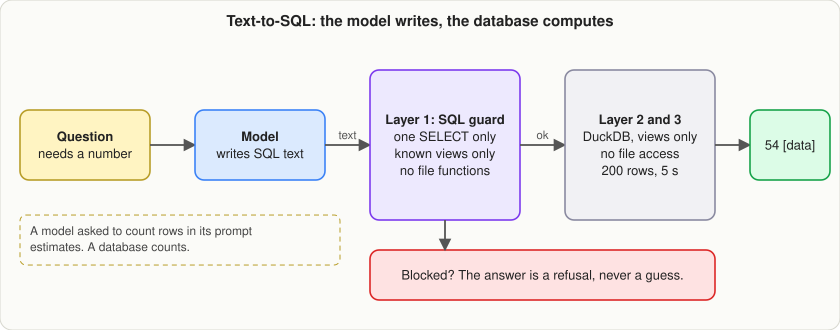

In [1]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))


diagram(840, 330, [
    ("box", 20, 110, 130, 70, "Question\nneeds a number", "gold"),
    ("arrow", 150, 145, 195, 145, ""),
    ("box", 195, 110, 130, 70, "Model\nwrites SQL text", "blue"),
    ("arrow", 325, 145, 370, 145, "text"),
    ("box", 370, 70, 150, 150, "Layer 1: SQL guard\none SELECT only\nknown views only\nno file functions", "violet"),
    ("arrow", 520, 145, 565, 145, "ok"),
    ("box", 565, 70, 150, 150, "Layer 2 and 3\nDuckDB, views only\nno file access\n200 rows, 5 s", "grey"),
    ("arrow", 715, 145, 750, 145, ""),
    ("box", 750, 110, 80, 70, "54 [data]", "green"),
    ("box", 370, 250, 345, 50, "Blocked? The answer is a refusal, never a guess.", "red"),
    ("arrow", 445, 220, 445, 250, ""),
    ("note", 20, 215, 320, 50, "A model asked to count rows in its prompt\nestimates. A database counts."),
], "Text-to-SQL: the model writes, the database computes")

## 1. The data

A small synthetic dataset for the Harbourview farm, generated here so the notebook is self-contained:
`turbines` (one row per turbine), `work_orders` (maintenance jobs with an alarm level) and `monthly_output`
(energy per turbine and month). It is loaded into DuckDB, an in-process analytical database that needs no
server and loads Python rows directly.

In [2]:
# The Harbourview handbook: 22 passages, fictional, written for this course
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, question, gold passage, fact the answer must contain); None = the handbook does not say
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [3]:
import re, json, math, time, threading, textwrap, datetime
import numpy as np, duckdb

rng = np.random.default_rng(42)
turbines = [(f"HV{i:02d}", 8.0, int(y)) for i, y in zip(range(1, 41), rng.choice([2022, 2023], 40, p=[.6, .4]))]
months = [f"2025-{m:02d}" for m in range(1, 13)]
season = {m: 1.25 - 0.45 * math.cos((int(m[5:]) - 1) / 12 * 2 * math.pi) / 2 for m in months}
monthly_output = [(t[0], m, round(float(8.0 * 24 * 30 * 0.38 * season[m] * rng.normal(1, .06)), 1)) for t in turbines for m in months]
cats = ["gearbox", "pitch", "yaw", "blade", "grid", "other"]
n = 300
day0 = datetime.date(2025, 1, 1)
work_orders = []
for i in range(1, n + 1):
    status = str(rng.choice(["closed", "open"], p=[.9, .1]))
    work_orders.append((f"WO{i:04d}", str(rng.choice([t[0] for t in turbines])), day0 + datetime.timedelta(days=int(rng.integers(0, 365))),
                        str(rng.choice(cats, p=[.15, .25, .15, .15, .1, .2])), int(rng.choice([1, 2, 3], p=[.45, .4, .15])),
                        round(float(rng.gamma(2.0, 14.0)), 1) if status == "closed" else None, status))
print(len(turbines), "turbines,", len(work_orders), "work orders,", len(monthly_output), "monthly output rows")
for row in work_orders[:3]:
    print(row)

40 turbines, 300 work orders, 480 monthly output rows
('WO0001', 'HV09', datetime.date(2025, 11, 3), 'other', 1, 59.0, 'closed')
('WO0002', 'HV34', datetime.date(2025, 10, 3), 'yaw', 2, 17.4, 'closed')
('WO0003', 'HV38', datetime.date(2025, 1, 17), 'pitch', 1, None, 'open')


## 2. The database: views only, no file access

The model never sees table names of the real storage. We load the data into tables, expose three **views**
with short, documented names, and then lock the connection: **no file system or network access** and no
configuration changes. Even if a query slipped past every other check, it could not read `/etc/passwd`.

In [4]:
con = duckdb.connect(":memory:")
con.execute("CREATE TABLE t_turbines (turbine_id VARCHAR, rated_mw DOUBLE, commissioned INTEGER)")
con.execute("CREATE TABLE t_work_orders (wo_id VARCHAR, turbine_id VARCHAR, opened DATE, category VARCHAR, alarm_level INTEGER, hours_to_close DOUBLE, status VARCHAR)")
con.execute("CREATE TABLE t_monthly_output (turbine_id VARCHAR, month VARCHAR, energy_mwh DOUBLE)")
con.executemany("INSERT INTO t_turbines VALUES (?, ?, ?)", turbines)
con.executemany("INSERT INTO t_work_orders VALUES (?, ?, ?, ?, ?, ?, ?)", work_orders)
con.executemany("INSERT INTO t_monthly_output VALUES (?, ?, ?)", monthly_output)
con.execute("CREATE VIEW turbines AS SELECT * FROM t_turbines")
con.execute("CREATE VIEW work_orders AS SELECT * FROM t_work_orders")
con.execute("CREATE VIEW monthly_output AS SELECT * FROM t_monthly_output")
con.execute("SET enable_external_access = false")      # no files, no network
con.execute("SET lock_configuration = true")           # the setting above can no longer be changed

try:
    con.execute("SELECT * FROM read_csv('/etc/passwd')")
except Exception as e:
    print("file access:", str(e).split(chr(10))[0][:110])
try:
    con.execute("SET enable_external_access = true")
except Exception as e:
    print("unlock attempt:", str(e).split(chr(10))[0][:110])

VIEWS = {
    "turbines": "one row per turbine: turbine_id (e.g. HV07), rated_mw, commissioned (year)",
    "work_orders": "maintenance jobs of 2025: wo_id, turbine_id, opened (date), category (gearbox|pitch|yaw|blade|grid|other), alarm_level (1-3), hours_to_close (NULL while open), status (closed|open)",
    "monthly_output": "energy per turbine and month of 2025: turbine_id, month ('YYYY-MM'), energy_mwh",
}
SCHEMA = "\n".join(f"- {v}: {d}" for v, d in VIEWS.items())
print(SCHEMA)

file access: Permission Error: Cannot access file "/etc/passwd" - file system operations are disabled by configuration
unlock attempt: Invalid Input Error: Cannot change configuration option ""enable_external_access"" - the configuration has bee
- turbines: one row per turbine: turbine_id (e.g. HV07), rated_mw, commissioned (year)
- work_orders: maintenance jobs of 2025: wo_id, turbine_id, opened (date), category (gearbox|pitch|yaw|blade|grid|other), alarm_level (1-3), hours_to_close (NULL while open), status (closed|open)
- monthly_output: energy per turbine and month of 2025: turbine_id, month ('YYYY-MM'), energy_mwh


## 3. The model writes the query (the prompt, and a stand-in)

This is the real prompt shape. Three things matter: the model sees **only** the documented views, it is told
to answer with **one** SELECT, and it is told what to do when the data cannot answer.

In [5]:
SQL_PROMPT = '''You write one read-only DuckDB SQL query that answers the user's question from these views:
{schema}
Rules:
- Return ONLY the SQL, a single SELECT (or WITH ... SELECT). No comments, no explanation.
- Use only the views and columns listed above.
- Aggregate in SQL: never return raw rows when the question asks for a count, a total or a ranking.
- If the views cannot answer the question, return exactly: NO_QUERY
Question: {question}'''
print(SQL_PROMPT.format(schema=SCHEMA, question="How many work orders were opened in March?"))

You write one read-only DuckDB SQL query that answers the user's question from these views:
- turbines: one row per turbine: turbine_id (e.g. HV07), rated_mw, commissioned (year)
- work_orders: maintenance jobs of 2025: wo_id, turbine_id, opened (date), category (gearbox|pitch|yaw|blade|grid|other), alarm_level (1-3), hours_to_close (NULL while open), status (closed|open)
- monthly_output: energy per turbine and month of 2025: turbine_id, month ('YYYY-MM'), energy_mwh
Rules:
- Return ONLY the SQL, a single SELECT (or WITH ... SELECT). No comments, no explanation.
- Use only the views and columns listed above.
- Aggregate in SQL: never return raw rows when the question asks for a count, a total or a ranking.
- If the views cannot answer the question, return exactly: NO_QUERY
Question: How many work orders were opened in March?


No model is called in the executed notebook. The function below is a **deterministic stand-in**: a handful
of templates that play the model's part so every result is reproducible. It also reproduces the most common
real mistake of a model, *inventing a column name* (`produced_mwh` instead of `energy_mwh`), so that we can
test the error-feedback retry honestly. An optional cell at the end of the notebook swaps in a real model
through LiteLLM when you set an environment variable.

In [6]:
import difflib

COLUMNS = {"turbines": ["turbine_id", "rated_mw", "commissioned"],
           "work_orders": ["wo_id", "turbine_id", "opened", "category", "alarm_level", "hours_to_close", "status"],
           "monthly_output": ["turbine_id", "month", "energy_mwh"]}

def stand_in_writer(question, error=None, previous=None):
    q = question.lower()
    if error and previous:                                     # retry: repair an unknown column from the error text
        bad = re.search(r'Referenced column "([^"]+)"', error)
        view = re.search(r"\bFROM\s+(\w+)", previous, re.I)
        if bad and view and view.group(1) in COLUMNS:
            close = difflib.get_close_matches(bad.group(1), COLUMNS[view.group(1)], n=1, cutoff=0.0)
            return previous.replace(bad.group(1), close[0])
        return previous
    m = re.search(r"level (\d)", q)
    if "work order" in q and "level" in q and m:
        return f"SELECT count(*) AS n FROM work_orders WHERE alarm_level = {m.group(1)}"
    if "work order" in q and ("how many" in q) and re.search(r"opened in (\w+)", q):
        month = {"january": 1, "february": 2, "march": 3, "april": 4, "may": 5, "june": 6}.get(re.search(r"opened in (\w+)", q).group(1))
        if month:
            return f"SELECT count(*) AS n FROM work_orders WHERE month(opened) = {month}"
    if "most energy" in q or "produced the most" in q:
        return "SELECT turbine_id, sum(produced_mwh) AS total_mwh FROM monthly_output GROUP BY turbine_id ORDER BY total_mwh DESC LIMIT 1"
    if "commissioned in" in q:
        y = re.search(r"commissioned in (\d{4})", q).group(1)
        return f"SELECT count(*) AS n FROM turbines WHERE commissioned = {y}"
    if "total" in q and "output" in q:
        mon = re.search(r"in (\w+)", q)
        num = {"january": 1, "february": 2, "march": 3, "april": 4, "may": 5, "june": 6, "july": 7, "august": 8}.get(mon.group(1)) if mon else None
        if num:
            return f"SELECT round(sum(energy_mwh), 1) AS total_mwh FROM monthly_output WHERE month = '2025-{num:02d}'"
    if "average" in q and "hours" in q and "pitch" in q:
        return "SELECT round(avg(hours_to_close), 1) AS avg_hours FROM work_orders WHERE category = 'pitch' AND status = 'closed'"
    return "NO_QUERY"

print(stand_in_writer("How many Level 3 work orders were there?"))

SELECT count(*) AS n FROM work_orders WHERE alarm_level = 3


## 4. The SQL guard

Text from a model is untrusted input. The guard decides whether a query may run, and it must be **strict by
construction**: instead of searching the text for bad words (easy to evade with comments, quoting or case),
it asks DuckDB's own parser for the **syntax tree** and checks the tree:

1. exactly **one** statement;
2. that statement is a **SELECT** (DuckDB refuses to serialise anything else, so `DROP`, `INSERT`, `COPY`, `ATTACH`, `PRAGMA` fail here);
3. every table it reads is one of our **views** or a CTE defined in the query itself, with **no schema prefix**;
4. **no table functions** at all (`read_csv`, `read_parquet`, `glob`, `range`...), which are how files and generators get in.

A parser-based guard cannot be fooled by `/* DROP */` or `ReAd_CsV`, because it never reads the text the way
a human would.

In [7]:
class Blocked(Exception):
    pass

def tables_of(node, out):
    if isinstance(node, dict):
        if node.get("type") in ("BASE_TABLE", "TABLE_FUNCTION"):
            out.append((node["type"], node.get("table_name"), node.get("schema_name") or ""))
        for v in node.values():
            tables_of(v, out)
    elif isinstance(node, list):
        for v in node:
            tables_of(v, out)

def cte_names(tree):
    names = set()
    def walk(node):
        if isinstance(node, dict):
            if "cte_map" in node:
                names.update(e["key"] for e in node["cte_map"]["map"])
            for v in node.values():
                walk(v)
        elif isinstance(node, list):
            for v in node:
                walk(v)
    walk(tree)
    return names

def guard(sql):
    sql = sql.strip().rstrip(";").strip()
    if not sql:
        raise Blocked("empty query")
    if len(con.extract_statements(sql)) != 1:
        raise Blocked("more than one statement")
    tree = json.loads(con.execute("SELECT json_serialize_sql(?)", [sql]).fetchone()[0])
    if tree.get("error"):
        raise Blocked("not a plain SELECT: " + tree.get("error_message", "")[:60])
    refs = []
    tables_of(tree, refs)
    ctes = cte_names(tree)
    for kind, name, schema in refs:
        if kind == "TABLE_FUNCTION":
            raise Blocked("table functions are not allowed")
        if schema:
            raise Blocked(f"schema-qualified table {schema}.{name}")
        if name not in VIEWS and name not in ctes:
            raise Blocked(f"unknown table {name!r} (allowed: {', '.join(VIEWS)})")
    return sql

LEGIT = [
    "SELECT count(*) FROM work_orders WHERE alarm_level = 3",
    "SELECT turbine_id, sum(energy_mwh) AS t FROM monthly_output GROUP BY 1 ORDER BY t DESC LIMIT 3",
    "WITH l3 AS (SELECT turbine_id FROM work_orders WHERE alarm_level = 3) SELECT count(DISTINCT turbine_id) FROM l3",
    "SELECT w.category, count(*) FROM work_orders w JOIN turbines t USING (turbine_id) WHERE t.commissioned = 2022 GROUP BY 1",
    "select 1 /* a harmless comment */ as one",
]
ATTACKS = [
    "DROP TABLE t_work_orders",
    "SELECT 1; DROP TABLE t_work_orders",
    "SELECT * FROM work_orders; SELECT * FROM turbines",
    "DELETE FROM work_orders",
    "INSERT INTO turbines VALUES ('X', 1, 2020)",
    "CREATE TABLE x AS SELECT * FROM turbines",
    "COPY work_orders TO '/tmp/leak.csv'",
    "ATTACH '/tmp/other.db' AS o",
    "PRAGMA database_list",
    "SET enable_external_access = true",
    "SELECT * FROM read_csv('/etc/passwd')",
    "SELECT * FROM ReAd_CsV('/etc/passwd')",
    "SELECT * FROM read_parquet('/data/*.parquet')",
    "SELECT * FROM glob('/home/*')",
    "SELECT * FROM range(1000000000)",
    "SELECT * FROM t_work_orders",
    "SELECT * FROM main.work_orders",
    "SELECT * FROM information_schema.tables",
    "SELECT * FROM duckdb_settings()",
    "/* DROP TABLE x */ SELECT 1; DROP TABLE x",
    "SELECT * FROM work_orders, secrets",
    "WITH x AS (SELECT * FROM read_csv('/etc/passwd')) SELECT * FROM x",
    "SELECT (SELECT count(*) FROM t_turbines)",
]

def check(sql):
    try:
        guard(sql); return "allowed"
    except Blocked as e:
        return "blocked: " + str(e)
    except Exception as e:
        return "blocked (parser): " + str(e).split(chr(10))[0][:50]

print("LEGITIMATE QUERIES")
for s in LEGIT:
    print(f"  {check(s)[:11]:12s} {s[:80]}")
print("\nATTACKS")
res = [(s, check(s)) for s in ATTACKS]
for s, r in res:
    print(f"  {r[:62]:62s} {s[:60]}")
assert all(check(s) == "allowed" for s in LEGIT), "a legitimate query was blocked"
assert all(r.startswith("blocked") for _, r in res), "an attack got through"
print(f"\n{sum(check(s) == 'allowed' for s in LEGIT)}/{len(LEGIT)} legitimate queries pass, {sum(r.startswith('blocked') for _, r in res)}/{len(ATTACKS)} attacks blocked")

LEGITIMATE QUERIES
  allowed      SELECT count(*) FROM work_orders WHERE alarm_level = 3
  allowed      SELECT turbine_id, sum(energy_mwh) AS t FROM monthly_output GROUP BY 1 ORDER BY 
  allowed      WITH l3 AS (SELECT turbine_id FROM work_orders WHERE alarm_level = 3) SELECT cou
  allowed      SELECT w.category, count(*) FROM work_orders w JOIN turbines t USING (turbine_id
  allowed      select 1 /* a harmless comment */ as one

ATTACKS
  blocked: not a plain SELECT: Only SELECT statements can be ser DROP TABLE t_work_orders
  blocked: more than one statement                               SELECT 1; DROP TABLE t_work_orders
  blocked: more than one statement                               SELECT * FROM work_orders; SELECT * FROM turbines
  blocked: not a plain SELECT: Only SELECT statements can be ser DELETE FROM work_orders
  blocked: not a plain SELECT: Only SELECT statements can be ser INSERT INTO turbines VALUES ('X', 1, 2020)
  blocked: not a plain SELECT: Only SELECT statements ca

Every attack is stopped, and each is stopped for a **named reason**, which matters in production: the
reason is logged (module 08) and shown to the model for its retry. Notice the two cases we block even though
they are not obviously dangerous: `t_work_orders` (a base table that is not part of the model's documented
world) and `information_schema` (it would let a model, or a user, explore the schema). *Least privilege*
means the model gets the views it needs and nothing else.

The guard is the first of **three layers**. The second is the locked connection of section 2 (no file or
network access even if the guard had a bug). The third limits what a legitimate query can cost: a row cap
and a timeout.

## 5. Running it: row cap, timeout, and one retry with the error

* **Row cap**: fetch at most 200 rows and say when the result was truncated. A model that forgot a `LIMIT`
  must not be able to push a million rows into the next prompt.
* **Timeout**: a watchdog thread calls `con.interrupt()` after a deadline. We demonstrate it with a query that
  the guard would never allow (a billion-row range), to show that the *third* layer works on its own.
* **Retry with the error**: if the query fails (a column that does not exist), pass the database's error
  message back to the model **once**. Two attempts is a good default: a second failure usually means the
  question cannot be answered from these views, and looping further only burns tokens.

### Picture: one question through the retry loop

This is the data path of the first retry example below. The stand-in writer makes the most common real mistake,
inventing the column `produced_mwh`. The guard lets the query through, because it is a valid SELECT over a known view,
and the database rejects it with a binder error. That error goes back to the writer once; the repaired query returns
`HV23`, which matches the independent calculation.

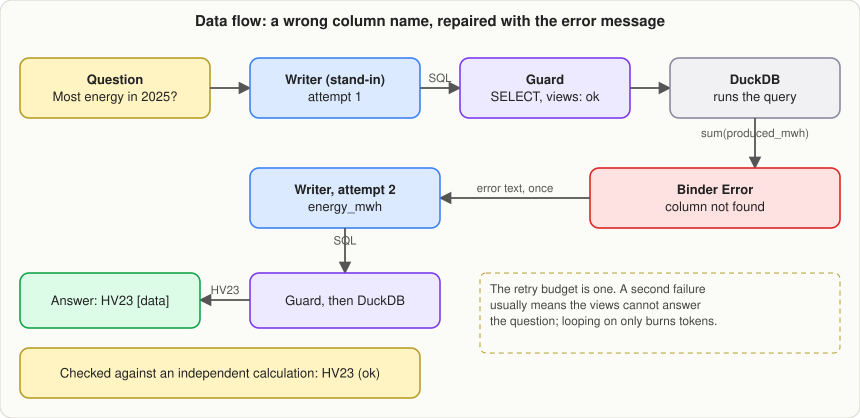

In [8]:
diagram(860, 418, [
    ("box", 20, 58, 190, 60, "Question\nMost energy in 2025?", "gold"),
    ("arrow", 210, 88, 250, 88, ""),
    ("box", 250, 58, 170, 60, "Writer (stand-in)\nattempt 1", "blue"),
    ("arrow", 420, 88, 460, 88, "SQL"),
    ("box", 460, 58, 170, 60, "Guard\nSELECT, views: ok", "violet"),
    ("arrow", 630, 88, 670, 88, ""),
    ("box", 670, 58, 170, 60, "DuckDB\nruns the query", "grey"),
    ("arrow", 755, 118, 755, 168, "sum(produced_mwh)"),
    ("box", 590, 168, 250, 60, "Binder Error\ncolumn not found", "red"),
    ("arrow", 590, 198, 440, 198, "error text, once"),
    ("box", 250, 168, 190, 60, "Writer, attempt 2\nenergy_mwh", "blue"),
    ("arrow", 345, 228, 345, 273, "SQL"),
    ("box", 250, 273, 190, 55, "Guard, then DuckDB", "violet"),
    ("arrow", 250, 300, 200, 300, "HV23"),
    ("box", 20, 273, 180, 55, "Answer: HV23 [data]", "green"),
    ("box", 20, 348, 400, 50, "Checked against an independent calculation: HV23 (ok)", "gold"),
    ("note", 480, 273, 360, 80, "The retry budget is one. A second failure\nusually means the views cannot answer\nthe question; looping on only burns tokens."),
], "Data flow: a wrong column name, repaired with the error message")

In [9]:
MAX_ROWS, TIMEOUT_S = 200, 5.0

def run_sql(sql, timeout=TIMEOUT_S):
    sql = guard(sql)
    timer = threading.Timer(timeout, con.interrupt)
    timer.start()
    try:
        cur = con.execute(sql)
        rows = cur.fetchmany(MAX_ROWS + 1)
        cols = [d[0] for d in cur.description]
    finally:
        timer.cancel()
    return dict(sql=sql, columns=cols, rows=[list(r) for r in rows[:MAX_ROWS]], truncated=len(rows) > MAX_ROWS)

# the third layer on its own: the guard would refuse this query, so call the database directly
t0 = time.time()
timer = threading.Timer(0.5, con.interrupt); timer.start()
try:
    con.execute("SELECT count(*) FROM generate_series(1, 100000000000)").fetchall()
except Exception as e:
    print(f"interrupted after {time.time() - t0:.2f} s:", type(e).__name__)
finally:
    timer.cancel()

def answer_with_sql(question, writer=stand_in_writer):
    attempts = []
    sql = writer(question)
    if sql.strip() == "NO_QUERY":
        return dict(status="no_query", attempts=attempts)
    error = None
    for attempt in (1, 2):
        try:
            result = run_sql(sql)
            attempts.append(dict(sql=sql, error=None))
            return dict(status="ok", result=result, attempts=attempts)
        except Exception as e:
            error = str(e).split(chr(10))[0]
            attempts.append(dict(sql=sql, error=error))
            if isinstance(e, Blocked) or attempt == 2:
                break
            sql = writer(question, error=error, previous=sql)
    return dict(status="failed", attempts=attempts)

out = answer_with_sql("Which turbine produced the most energy in 2025?")
for a in out["attempts"]:
    print("attempt:", a["sql"][:95], "\n   error:", a["error"])
print("result:", out["result"]["columns"], out["result"]["rows"])

interrupted after 0.50 s: InterruptException
attempt: SELECT turbine_id, sum(produced_mwh) AS total_mwh FROM monthly_output GROUP BY turbine_id ORDER 
   error: Binder Error: Referenced column "produced_mwh" not found in FROM clause!
attempt: SELECT turbine_id, sum(energy_mwh) AS total_mwh FROM monthly_output GROUP BY turbine_id ORDER B 
   error: None
result: ['turbine_id', 'total_mwh'] [['HV23', 34052.399999999994]]


The first attempt failed with the database's own message, the stand-in repaired the column from that message
(a real model does the same with the schema in its prompt), and the second attempt ran. The log of **both**
attempts is kept: a question that needs a retry is a signal about the prompt, not about the user.

## 6. Citing data like a passage

An answer from data is as unverifiable as an answer from memory unless it shows where it came from. We
cite passages as `[1]`, `[2]` and the query result as **`[data]`**, and we keep the SQL next to the answer so
a reader (or the supervisor of module 08) can re-run it.

In [10]:
STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
def tokens(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.tf = [{} for _ in docs]
        for i, d in enumerate(docs):
            for t in tokens(d):
                self.tf[i][t] = self.tf[i].get(t, 0) + 1
        self.len = np.array([sum(tf.values()) for tf in self.tf], dtype=float); self.avg = self.len.mean()
        df = {}
        for tf in self.tf:
            for t in tf:
                df[t] = df.get(t, 0) + 1
        self.idf = {t: math.log(1 + (len(docs) - c + 0.5) / (c + 0.5)) for t, c in df.items()}
    def scores(self, query):
        s = np.zeros(len(self.tf))
        for t in set(tokens(query)):
            if t in self.idf:
                for i, tf in enumerate(self.tf):
                    f = tf.get(t, 0)
                    if f:
                        s[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return s

ids = [p[0] for p in PASSAGES]
chunks = [f"{section}. {text}" for _, section, text in PASSAGES]
bm25 = BM25(chunks)

def best_sentence(question, passage_idx):
    section, text = chunks[passage_idx].split(". ", 1)
    q = set(tokens(question))
    return max(re.split(r"(?<=[.!?])\s+", text), key=lambda s: len(q & set(tokens(s)))), section

def format_data(out):
    cols, rows = out["result"]["columns"], out["result"]["rows"]
    if len(rows) == 1 and len(cols) == 1:
        return f"{cols[0]} = {rows[0][0]}"
    return "; ".join(", ".join(f"{c} = {v}" for c, v in zip(cols, r)) for r in rows[:5])

def respond(question, route):
    parts, sources = [], []
    if route in ("sql", "both"):
        out = answer_with_sql(question)
        if out["status"] == "ok":
            parts.append(f"From the data: {format_data(out)} [data].")
            sources.append(("data", out["attempts"][-1]["sql"]))
    if route in ("passages", "both"):
        s = bm25.scores(question); i = int(np.argmax(s))
        if s[i] >= 1.0:
            sent, section = best_sentence(question, i)
            parts.append(f"{sent} [1]")
            sources.append((1, f"{ids[i]} {section}"))
    return (" ".join(parts) or "I cannot answer that from the handbook or the data."), sources

ans, src = respond("How many Level 3 work orders were there, and how quickly must a Level 3 alarm be attended?", "both")
print(ans); print(src)

From the data: n = 54 [data]. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows. [1]
[('data', 'SELECT count(*) AS n FROM work_orders WHERE alarm_level = 3'), (1, 'p09 Faults / Alarm levels')]


## 7. Routing: passages, SQL or both?

Which path does a question need? A cheap, transparent router is a good start: *numbers and rankings over
our own records* go to SQL, *rules and procedures* go to passages, and a question that mixes them goes to
both. We test it on a labelled battery, because a router is a classifier and deserves a measurement.

In [11]:
DATA_WORDS = re.compile(r"\b(how many|total|average|mean|most|least|highest|lowest|sum|number of|count)\b", re.I)
DATA_NOUNS = re.compile(r"\b(work orders?|turbines?|output|energy|mwh|alarms?|opened|commissioned)\b", re.I)
RULE_WORDS = re.compile(r"\b(must|should|allowed|limit|rule|procedure|how (?:quickly|soon|often|fast)|when can|what is the|who)\b", re.I)

def route(question):
    wants_data = bool(DATA_WORDS.search(question) and DATA_NOUNS.search(question))
    wants_rule = bool(RULE_WORDS.search(question)) or not wants_data
    if wants_data and re.search(r"\band\b.*\b(must|how (?:quickly|soon|often|fast)|what is the (?:rule|limit))", question, re.I):
        return "both"
    return "sql" if wants_data and not RULE_WORDS.search(question) else ("both" if wants_data else "passages")

ROUTE_BATTERY = [
    ("How many Level 3 work orders were there?", "sql"),
    ("Which turbine produced the most energy in 2025?", "sql"),
    ("What was the total output in March in MWh?", "sql"),
    ("How many turbines were commissioned in 2023?", "sql"),
    ("What is the average number of hours to close a pitch work order?", "sql"),
    ("What wave height stops the crew boats from sailing?", "passages"),
    ("How often is the gearbox oil sampled?", "passages"),
    ("When can a helicopter be used?", "passages"),
    ("How many Level 3 work orders were there, and how quickly must a Level 3 alarm be attended?", "both"),
    ("Who is the chief executive of the operating company?", "none"),
]
right = 0
for q, expected in ROUTE_BATTERY:
    got = route(q)
    ok = got == expected or (expected == "none" and got == "passages")   # 'none' has no route: passages then refuses
    right += ok
    print(f"{'ok ' if ok else 'MISS'} expected {expected:9s} got {got:9s} {q[:70]}")
print(f"\nrouting: {right}/{len(ROUTE_BATTERY)}")

ok  expected sql       got sql       How many Level 3 work orders were there?
ok  expected sql       got sql       Which turbine produced the most energy in 2025?
ok  expected sql       got sql       What was the total output in March in MWh?
ok  expected sql       got sql       How many turbines were commissioned in 2023?
MISS expected sql       got both      What is the average number of hours to close a pitch work order?
ok  expected passages  got passages  What wave height stops the crew boats from sailing?
ok  expected passages  got passages  How often is the gearbox oil sampled?
ok  expected passages  got passages  When can a helicopter be used?
ok  expected both      got both      How many Level 3 work orders were there, and how quickly must a Level 
ok  expected none      got passages  Who is the chief executive of the operating company?

routing: 9/10


The router gets 9 of 10 right. The miss is instructive: *"What is the average number of hours ..."* contains
the phrase *"what is the"*, which our rule treats as a sign of a rule question, so it sends a pure data
question to both paths (harmless but wasteful: it also retrieves a passage). The CEO question is counted as
correct because the passage path finds nothing above the threshold and the answer refuses. Read misses
as a to-do list for the router, not as a failure of the idea. In production the
router is often the **model itself** (it is told it has two tools, a passage search and a SQL query, and
chooses), which is what module 05's agents do; a rule-based router like this one is the baseline to beat
and a useful fallback when the model is unavailable.

## 8. Checking the answers against an independent calculation

How do we know the SQL answers are right? The same way as for any component: compare against a reference
computed **independently**, here with plain Python on the raw rows rather than SQL. Module 07 turns this into a
full evaluation habit: *the reference must never come from the system under test.*

In [12]:
QA = [
    ("How many Level 3 work orders were there?", sum(w[4] == 3 for w in work_orders)),
    ("How many turbines were commissioned in 2023?", sum(t[2] == 2023 for t in turbines)),
    ("What was the total output in March in MWh?", round(sum(r[2] for r in monthly_output if r[1] == "2025-03"), 1)),
    ("What is the average number of hours to close a pitch work order?",
     round(float(np.mean([w[5] for w in work_orders if w[3] == "pitch" and w[6] == "closed"])), 1)),
    ("Which turbine produced the most energy in 2025?", max(totals := {t[0]: sum(r[2] for r in monthly_output if r[0] == t[0]) for t in turbines}, key=totals.get)),
]
for q, ref in QA:
    out = answer_with_sql(q)
    got = out["result"]["rows"][0][0] if out["status"] == "ok" else None
    ok = got == ref
    print(f"{'ok  ' if ok else 'FAIL'} {q[:62]:62s} sql={got!s:>8}  reference={ref!s:>8}  retries={len(out['attempts']) - 1}")

ok   How many Level 3 work orders were there?                       sql=      54  reference=      54  retries=0
ok   How many turbines were commissioned in 2023?                   sql=      19  reference=      19  retries=0
ok   What was the total output in March in MWh?                     sql= 99600.0  reference= 99600.0  retries=0
ok   What is the average number of hours to close a pitch work orde sql=    25.4  reference=    25.4  retries=0
ok   Which turbine produced the most energy in 2025?                sql=    HV23  reference=    HV23  retries=1


## 9. Optional: a real model writes the SQL

The executed notebook never calls a model. To try a real one, set `RAG_LIVE_MODEL` to a LiteLLM model name
(for example a Bedrock Amazon Nova model, or any hosted model you have a key for) and re-run this cell. It
plugs into exactly the same guard, executor and retry, which is the point: **the safety does not depend on
the model**. Without the variable the cell does nothing.

In [13]:
import os

def litellm_writer(question, error=None, previous=None):
    import litellm
    prompt = SQL_PROMPT.format(schema=SCHEMA, question=question)
    if error:
        prompt += f"\n\nYour previous query:\n{previous}\nfailed with:\n{error}\nReturn a corrected query."
    r = litellm.completion(model=os.environ["RAG_LIVE_MODEL"], messages=[{"role": "user", "content": prompt}], temperature=0)
    return r.choices[0].message.content.strip().strip("`").removeprefix("sql").strip()

if os.getenv("RAG_LIVE_MODEL"):
    print(answer_with_sql("Which turbine had the most Level 3 work orders?", writer=litellm_writer))
else:
    print("RAG_LIVE_MODEL is not set: skipped (the notebook uses the deterministic stand-in).")

RAG_LIVE_MODEL is not set: skipped (the notebook uses the deterministic stand-in).


## What the real system looked like

A retail supply-chain forecasting assistant built in this portfolio's projects used exactly this design: the
model writes **one** read-only SELECT over named views of the forecast result tables, DuckDB executes it with
the result **capped at 200 rows**, a failed query gets one retry with the error, and the answer cites
passages as `[n]` and the figures as `[data]`. The model never saw file paths, and a question the views
could not answer returned "not found" instead of an invented number.

## Exercises

1. Add three more attacks of your own (try a `UNION` against a hidden table, a comment trick, a quoted
   identifier such as `"t_turbines"`) and confirm the guard blocks them. Which layer stops each?
2. Remove `lock_configuration` and `enable_external_access` and re-run section 2. What does the guard alone
   prevent, and what does it not?
3. Make `MAX_ROWS` 3 and ask for all work orders. How would the answer text tell a reader the result was cut?
4. Extend `route` with one more rule, then add three questions to `ROUTE_BATTERY` that it gets wrong. Which
   kind of question is a rule-based router worst at?